In [4]:
import copy
import os
import math
import time

import numpy as np
import torch
from torch import nn, Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Dataset
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from typing import Literal, Tuple, Callable, NamedTuple
import pandas as pd

SEED = 2021
np.random.seed(SEED)
torch.manual_seed(SEED)

# render figures as crisp vector graphics
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device.")

Using cuda device.


In [5]:
class SeasonalNaive(nn.Module):
    """
    Seasonal naive baseline: predicted series are the last observed
    season (period), repeated.

    Step t of the forecast equals the value from `period` steps before it,
    so a period of 24h repeats the last day and 168h repeats the last week.
    """
    def __init__(self, period: int, prediction_size: int):
        super().__init__()
        self.period = period
        self.prediction_size = prediction_size

    def forward(self, X: Tensor) -> Tensor:
        """
        Input:  (batch, num_channels, lookback_size)
        Output: (batch, num_channels, prediction_size)
        """
        assert X.shape[-1] >= self.period, "lookback must be at least one period"

        last_season = X[..., -self.period:]
        reps = math.ceil(self.prediction_size / self.period)
        return last_season.tile((reps,))[..., :self.prediction_size]

In [6]:
def load_time_series_data(
    file_path: str,
    delimiter: str = ",",
    missing_values = "***",
    filling_values = 0,
) -> np.ndarray:
    """
    Load raw multivariate time-series data into a 2D float tensor of shape (T, num_channels).

    The file is expected to be a text file with no header row or index (time) column. I.e., it
    should directly be raw data rows. Each row must record a timestamp, and each column a channel
    of the multivariate series.
    """
    arr = np.genfromtxt(file_path,
                        delimiter=delimiter,
                        missing_values=missing_values,
                        filling_values=filling_values)
    if arr.ndim != 2:
        raise ValueError(f"Expected 2D tensor of shape (T, num_channels), got shape {arr.shape}")

    return arr


def to_data_loader(data: Dataset, batch_size: int, collate_fn=None, shuffle=False, seed=SEED) -> DataLoader:
    g = torch.Generator()
    g.manual_seed(seed)

    return DataLoader(
        data,
        batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn,
        generator=g)


def split_time_series_data(
    raw_data: np.ndarray,
    lookback_size: int,
    prediction_size: int,
    split_ratios: Tuple[float, float, float] = (0.7, 0.1, 0.2),
    batch_size: int = 24,
    dtype: torch.dtype = torch.float32,
) -> Tuple[
    DataLoader[TensorDataset],
    DataLoader[TensorDataset],
    DataLoader[TensorDataset],
    StandardScaler
]:
    """
    Construct a PyTorch TensorDataset containing (X, Y) sliding-window pairs. Each window pair
    logically consists of X_i = [...lookback_size...] historic time steps used to predict
    Y_i = [...prediction_size...] events into the future, for each channel.

    In other words,
        X[i] = data[i : i + lookback_size]^T    shape: (num_channels, lookback_size)
        Y[i] = data[i + lookback_size : i + lookback_size + prediction_size]^T
                                                shape: (num_channels, prediction_size)
    Returns:
       train/val/test: `DataLoader`s, containing `TensorDataset`s that have:
                tensors[0] (X): shape (N, num_channels, lookback_size)
                tensors[1] (Y): shape (N, num_channels, prediction_size)
            where N is the number of valid sliding windows. Data is standardized.

        scaler: the `StandardScaler` used to standardize the data, in order to
            reverse the process for plotting in the original scale of the data.
    """
    scaler = StandardScaler()
    has_fit = False
    def lookback_and_prediction_windows(split: np.ndarray) -> Dataset:
        nonlocal scaler, has_fit
        split = scaler.transform(split) if has_fit else scaler.fit_transform(split)
        has_fit = True

        # Stride of 1: heavily overlap samples.
        # Unfolding yields the shape (N_samples, channels, window_size)
        tensor = torch.from_numpy(split).to(dtype=dtype)
        X = tensor.unfold(dimension=0, size=lookback_size, step=1)
        Y = tensor[lookback_size:].unfold(dimension=0, size=prediction_size, step=1)

        num_samples = min(X.shape[0], Y.shape[0])
        dataset = TensorDataset(X[:num_samples], Y[:num_samples])

        return dataset

    num_timesteps, _ = raw_data.shape

    train_ratio, val_ratio, _ = split_ratios
    train_size = int(num_timesteps * train_ratio)
    val_size = int(num_timesteps * val_ratio)
    test_size = num_timesteps - train_size - val_size

    # Pull lookback windows in val/test from the split before it (predicted values
    # in val/test are never seen from another split).
    # This matches the offical code's implementation.
    train_dataset, val_dataset, test_dataset = map(lookback_and_prediction_windows, [
        raw_data[:train_size],
        raw_data[train_size - lookback_size:train_size + val_size],
        raw_data[num_timesteps - test_size - lookback_size:],
    ])

    return to_data_loader(train_dataset, batch_size, shuffle=True), \
            to_data_loader(val_dataset, batch_size), \
            to_data_loader(test_dataset, batch_size), \
            scaler

In [7]:
def evaluate(
        model: nn.Module,
        data_loader: DataLoader[TensorDataset],
        loss_fn: nn.Module,
        channel_chunk_size=96) -> float:
    # channel_chunk_size: Take small windows of channels to avoid running out of memory
    # on the GPU. This works with a validation/test dataloader that does not do any
    # windowing of channels (a plain TensorDataset), or one that is already windowing
    # RandomizedChannelDataset (in which case splitting here may only yield one item).
    model.eval()
    total_loss = 0.0
    count = 0
    with torch.no_grad():
        for batch in data_loader:  # (batch_size, channels, time_window_size)
            X, y = batch[0], batch[1]  # Work with TensorDataset or RandomizedChannelDataset

            for Xc, yc in zip(X.split(channel_chunk_size, dim=1), y.split(channel_chunk_size, dim=1)):
                Xc, yc = Xc.to(device), yc.to(device)
                total_loss += loss_fn(model(Xc), yc).item() * yc.numel()
                count += yc.numel()
    return total_loss / count

In [15]:
# NOTE: This only works with TensorDataset.
# `show_prediction_from_randomized_channel_set` works with RandomizedChannelDataset.
def show_random_prediction(
        models: list[nn.Module],
        loader: DataLoader[TensorDataset],
        scaler: StandardScaler,
        channel_labels: list[str] = []):
    # Grab the first sample from the first batch, channel 0.
    # When using the val loader, this sample starts on line 11,769 of
    # the full dataset.
    # The scaler expects items in the shape (time, num_channels).
    random_time = np.random.randint(0, len(loader.dataset))
    X, Y = loader.dataset[random_time]  # (channels, lookback/pred_size)
    channel = np.random.randint(0, len(X))
    sample = Tensor(scaler.inverse_transform(X.T).T[channel])
    truth = Tensor(scaler.inverse_transform(Y.T).T[channel])

    _, ax = plt.subplots(figsize=(10, 4))

    prediction_xticks = np.arange(len(sample), len(sample) + len(truth))
    l1 = ax.plot(sample, label='lookback window')
    l2 = ax.plot(prediction_xticks, truth,
                label='true future series')

    lines = l1 + l2
    for model in models:
        with torch.no_grad():
            single_sample_batch = X.unsqueeze(0)
            model = model.to(device)
            model.eval()
            all_preds = model(single_sample_batch.to(device)).cpu()
            preds = scaler.inverse_transform(all_preds[0].T).T[channel]

        # print("lookback window, future truth, future prediction",
        #     sample.shape, truth.shape, preds.shape)

        line = ax.plot(prediction_xticks, preds,
                    label='predicted future series')
        lines += line

    if channel_labels:
        plt.title(channel_labels[channel])
    ax.legend(lines, [ln.get_label() for ln in lines], bbox_to_anchor=(1.05, 1), loc='upper left');


In [11]:
all_traffic_data = load_time_series_data("./data/traffic.txt", delimiter=",")
traffic_train_loader, traffic_val_loader, _, traffic_scaler = split_time_series_data(
    all_traffic_data,
    lookback_size=336,
    prediction_size=96,
    batch_size=64)

## 24h period

This makes some intuitive sense. Just copy the last day over and over...

In [28]:
model_24 = SeasonalNaive(period=24, prediction_size=96)
print("SeasonalNaive 24h, L=96 loss (val) =", evaluate(model_24, traffic_val_loader, nn.MSELoss()))

SeasonalNaive 24h, L=96 loss (val) = 1.0519312118548951


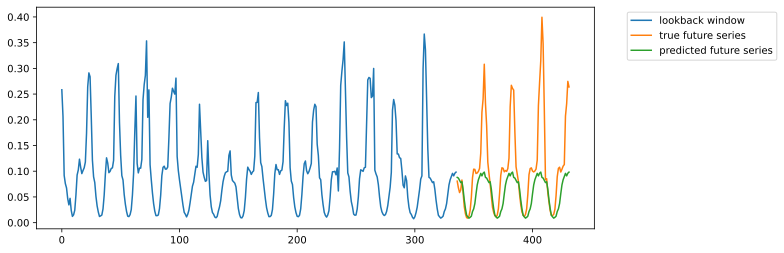

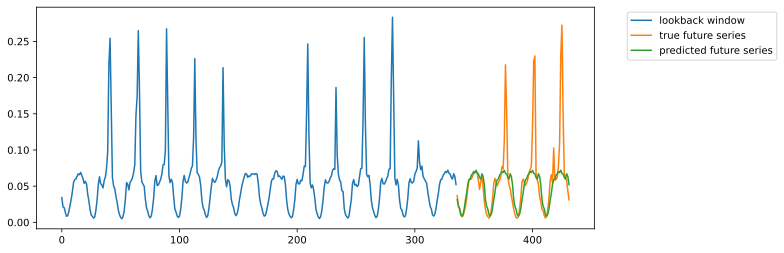

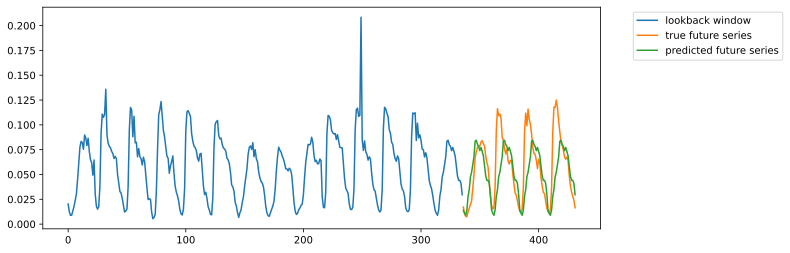

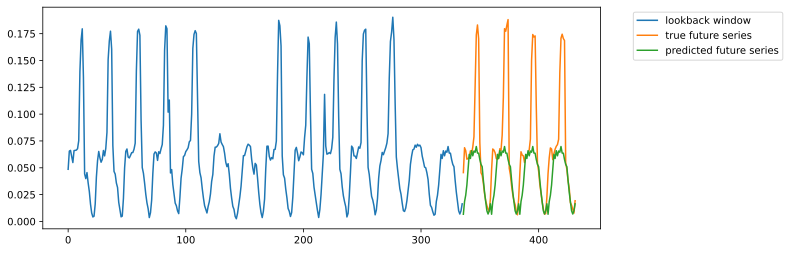

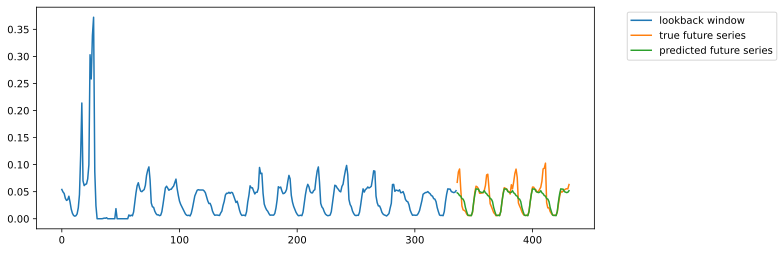

In [32]:
for _ in range(5):
    show_random_prediction(
        [model_24],
        traffic_val_loader,
        traffic_scaler)

## 96h period

Just copy the `prediction_size` amount of time from the past.

This feels natural to do, but the prediction window size is arbitrary and not aligned with the actual rhythm of this dataset (24h-ish, but really weekly).

SeasonalNaive 96h, L=96 loss (val) = 1.2384608506657213


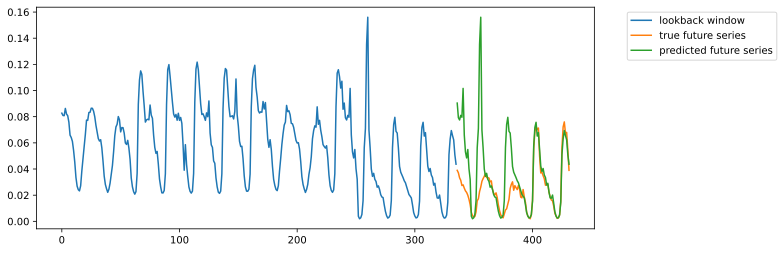

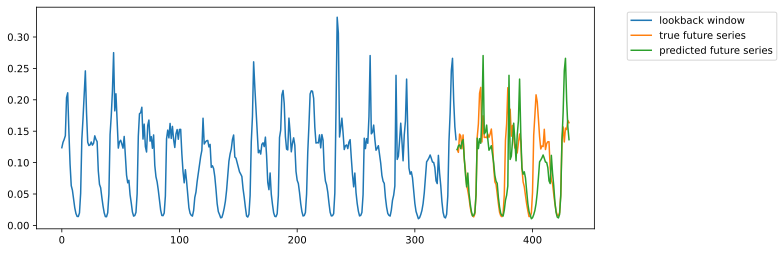

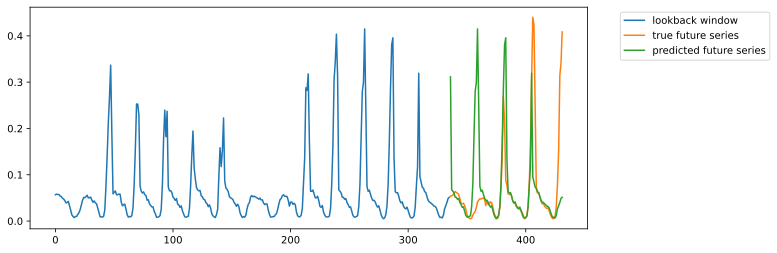

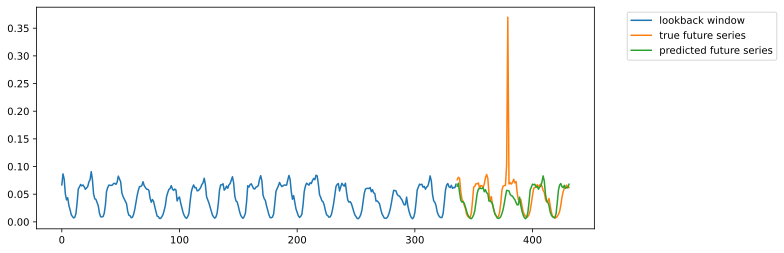

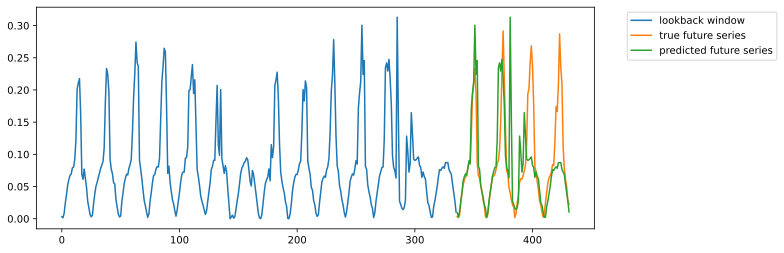

In [33]:
model_96 = SeasonalNaive(period=96, prediction_size=96)
print("SeasonalNaive 96h, L=96 loss (val) =", evaluate(model_96, traffic_val_loader, nn.MSELoss()))

for _ in range(5):
    show_random_prediction(
        [model_96],
        traffic_val_loader,
        traffic_scaler)

## 1 week period

This is the sweet spot—traffic data is _really_ cyclical on the order of a week. Probably the lowest loss value we'll see (but there is a sweep below)

SeasonalNaive 168h, L=96 loss (val) = 0.5147320064475007


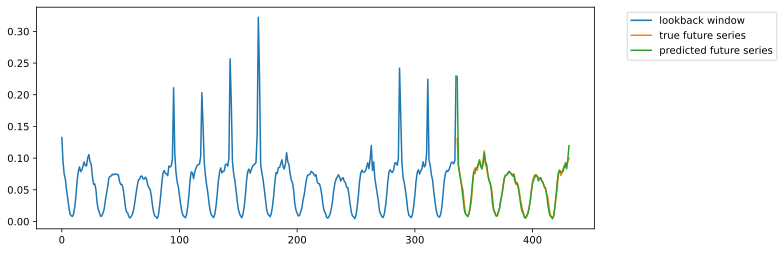

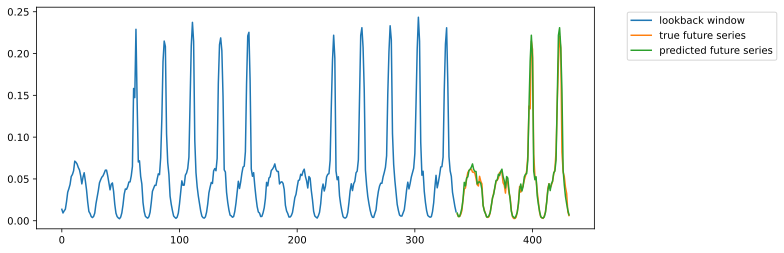

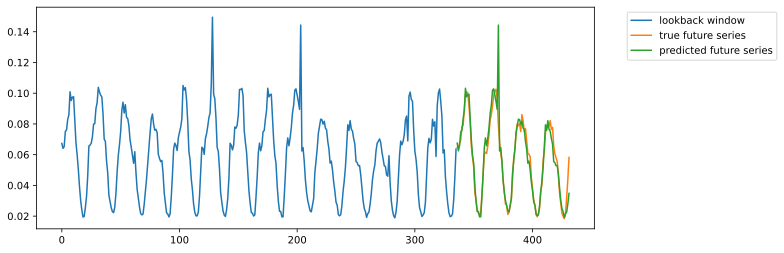

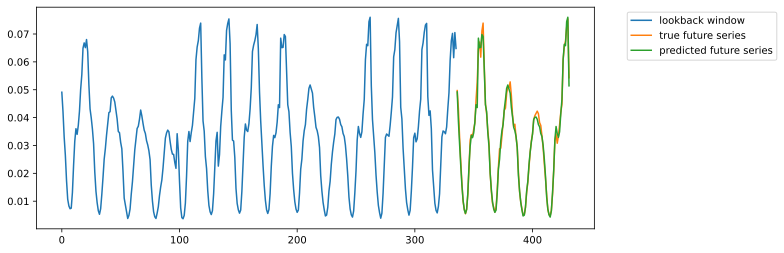

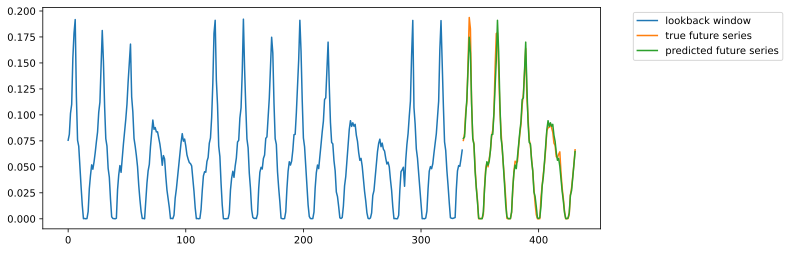

In [ ]:
model_168 = SeasonalNaive(period=168, prediction_size=96)
print("SeasonalNaive 168h, L=96 loss (val) =", evaluate(model_168, traffic_val_loader, nn.MSELoss()))

for _ in range(5):
    show_random_prediction(
        [model_168],
        traffic_val_loader,
        traffic_scaler)

## 720h prediction, 168h season


SeasonalNaive 168h, L=720 loss (val) = 0.5631270130343081


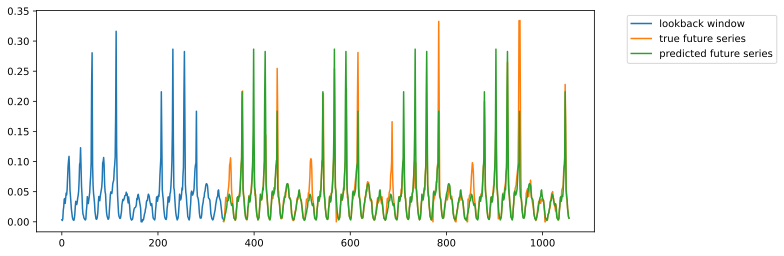

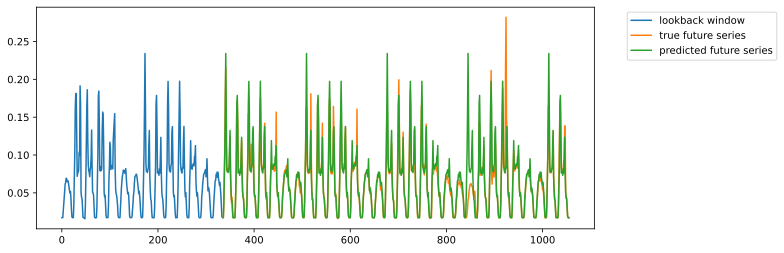

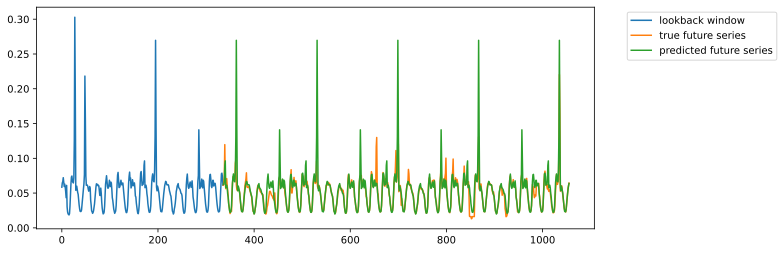

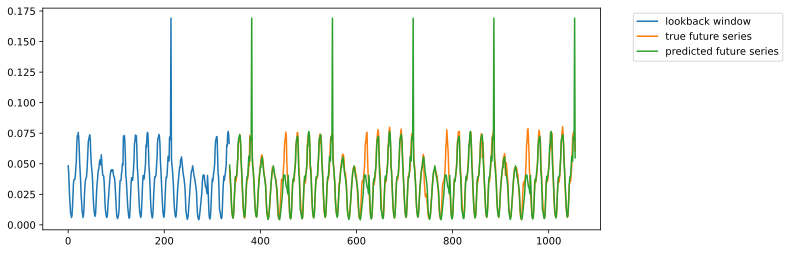

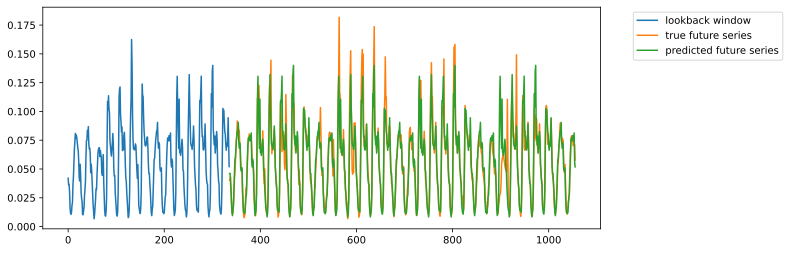

In [48]:
_, traffic_val_loader_big, _, _ = split_time_series_data(
    all_traffic_data,
    lookback_size=336,
    prediction_size=720,
    batch_size=64)

model_720 = SeasonalNaive(period=168, prediction_size=720)
print("SeasonalNaive 168h, L=720 loss (val) =", evaluate(model_720, traffic_val_loader_big, nn.MSELoss()))

for _ in range(5):
    show_random_prediction(
        [model_720],
        traffic_val_loader_big,
        traffic_scaler)

## Period sweep

It makes sense that the lowest loss values are aligned on the week boundaries.

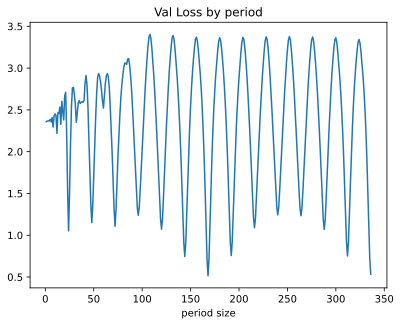

In [44]:
lookback_size = 336
losses = []
for i in range(1, lookback_size + 1):
    model = SeasonalNaive(period=i, prediction_size=96)
    loss = evaluate(model, traffic_val_loader, nn.MSELoss())
    losses.append(loss)

plt.plot(torch.arange(1, lookback_size + 1), losses)
plt.xlabel("period size")
plt.title("Val Loss by period");